# Blobs

Gooey metaballs: circles drift on closed loops inside one group under `svg.filters.goo`, which blurs the
group and sharpens its edge again, so blobs that come close stretch a bridge, merge, and split apart.

In [1]:
import functools

from IPython import display as ipy
import svgwriter as svg

from animations import drift
from components import body

The project's theme applies to everything below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)
theme.__enter__();

In [3]:
LOOP = 4.0          # seconds before the scene repeats at normal speed
MELT = 14           # how far apart blobs still reach for each other
BLOBS = (           # radius, loop width, loop height, turns, phase; the first is the large one
    (46, 0, 0, 1, 0.0),
    (30, 120, 40, 1, 0.0),
    (26, 110, 50, 1, 3.1),
    (22, 80, 70, 2, 1.6),
    (18, 160, 30, 1, 4.7),
    (24, 140, 60, 1, 1.1),
    (16, 100, 80, 2, 5.4),
    (20, 170, 20, 1, 2.3),
    (14, 60, 90, 1, 3.9),
)

The `drift` behaviour from `animations/` moves each circle; `self.attach` checks its options. Every
loop is a whole number of turns in one period, so the GIF and the baked SVG loop seamlessly. A faster
`speed` shortens the period, so the loop stays seamless at any speed.

In [4]:
class Blobs(svg.Scene):
    """Blobs merging and splitting around a large one."""

    width, height = 560, 320
    fps = 15

    def __init__(self, count: int = 5, melt: float = MELT, speed: float = 1.0) -> None:
        self.count, self.melt = count, melt
        self.duration = LOOP / speed
        super().__init__()

    def build(self, doc: svg.Document) -> None:
        doc.rect(0, 0, self.width, self.height).as_role("background")
        palette = doc.theme.palette
        cx, cy = self.width / 2, self.height / 2
        blobs = BLOBS[:self.count]
        circles = [svg.circle(cx, cy, radius) for radius, *_ in blobs]
        doc += body(circles, top=palette["secondary"], bottom=palette["primary"], height=self.height, melt=self.melt)
        for circle, (_, rx, ry, turns, phase) in zip(circles, blobs, strict=True):
            if rx or ry:
                self.attach(circle, drift, rx=rx, ry=ry, turns=turns, phase=phase, period=self.duration)
        glints = doc.group(fill="#ffffff", opacity=0.35)
        glints += svg.circle(cx - 14, cy - 18, 8)

The controls: how many blobs, how far they reach for each other (the goo filter's `melt`) and how fast
they move. The function bakes the scene into an animated document, so `svgwriter preview` shows the
form and plays the result, and `svg.interact` does the same in a notebook.

In [5]:
@svg.widgets.controls(
    count=svg.widgets.IntSlider(1, len(BLOBS), value=5, label="blobs"),
    melt=svg.widgets.Slider(4, 30, step=1, value=MELT, label="gooeyness"),
    speed=svg.widgets.Slider(0.5, 3, step=0.25, value=1.0),
)
def blobs(doc: svg.Document, *, count: int = 5, melt: float = MELT, speed: float = 1.0) -> svg.Document:
    """The blobs scene for these controls, baked into an animated document."""
    return Blobs(count, melt, speed).bake()

Every control of `blobs` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [6]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.interact(in_project(blobs))

The same function for other control values.

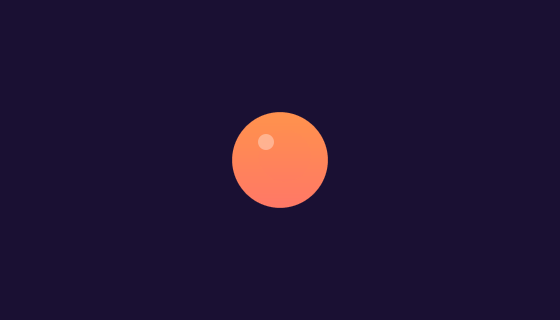

In [7]:
show(blobs, **{'count': 3, 'melt': 8})

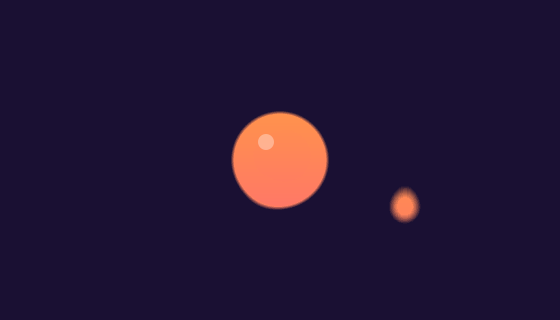

In [8]:
show(blobs, **{'count': 9, 'melt': 24, 'speed': 2.0})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

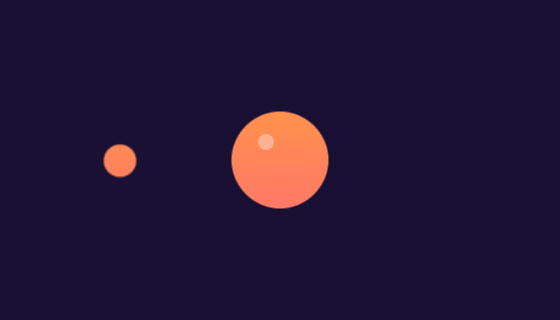

In [9]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))